#**HEALTHCARE INSURANCE FRAUD ANALYSIS**

#**INTRODUCTION**

This project explores insurance claim data using Python to identify patterns and relationships related to fraudulent claims through Exploratory Data Analysis (EDA).

**OBJECTIVES**



1. To understand insurance claim data.
2. To identify fraudulent and non-fraudulent claims.
3. To analyze claim amounts and claim status.
4. To examine factors related to insurance fraud.
5. To identify patterns using Python visualizations.

**IMPORT** **LIBRARIES**

In [88]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

**LOAD THE DATASET**

In [89]:
df=pd.read_csv('/healthcare_fraud_detection.csv')

In [90]:
df

,Provider_ID,Claim_ID,Patient_Age,Patient_Gender,Diagnosis_Code,Procedure_Code,Claim_Amount,Approved_Amount,Insurance_Type,Claim_Submission_Date,Days_Between_Service_and_Claim,Number_of_Claims_Per_Provider_Monthly,Provider_Specialty,Patient_State,Claim_Status,Is_Fraud,Length_of_Stay,Visit_Type,Chronic_Condition_Flag,Prior_Visits_12m
0,P0052,C0000000,37,Male,I25.10,36415,443.51,393.16,Medicaid,01-09-2024,13,70,Cardiology,NY,Approved,0,0,Outpatient,1,2.0
1,P0121,C0000001,21,Female,E11.9,99213,467.50,461.33,Self-Pay,05-09-2022,5,62,General Practice,IL,Pending,0,5,Inpatient,1,2.0
2,P0140,C0000002,78,Female,J06.9,93000,591.69,530.06,Medicaid,11-04-2022,29,60,Cardiology,IL,Pending,0,5,Inpatient,1,3.0
3,P0202,C0000003,65,Male,I10,93000,235.15,189.11,Private,11-10-2023,22,70,General Practice,TX,Approved,0,0,Emergency,0,5.0
4,P0135,C0000004,36,Male,M54.5,85025,487.96,369.91,Private,05-09-2023,21,67,Pulmonology,PA,Approved,0,5,Inpatient,0,4.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,P0289,C0009995,79,Male,E78.5,71046,590.19,205.00,Private,24-09-2024,2,115,Internal Medicine,PA,Approved,1,2,Inpatient,1,3.0
9996,P0248,C0009996,66,Male,K21.9,93000,219.73,191.89,Self-Pay,04-01-2023,6,73,Orthopedics,IL,Approved,0,5,Inpatient,0,6.0
9997,P0122,C0009997,43,Female,F41.9,99213,505.24,447.94,Medicare,30-06-2024,6,59,Neurology,OH,Rejected,0,5,Emergency,1,0.0
9998,P0072,C0009998,39,Female,I10,93000,564.25,507.18,Medicare,15-03-2022,8,55,Cardiology,TX,Pending,0,5,Emergency,0,6.0


**UNDERSTAND THE DATASET**

In [91]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 20 columns):
 #   Column                                 Non-Null Count  Dtype  
---  ------                                 --------------  -----  
 0   Provider_ID                            10000 non-null  object 
 1   Claim_ID                               10000 non-null  object 
 2   Patient_Age                            10000 non-null  int64  
 3   Patient_Gender                         10000 non-null  object 
 4   Diagnosis_Code                         10000 non-null  object 
 5   Procedure_Code                         10000 non-null  int64  
 6   Claim_Amount                           10000 non-null  float64
 7   Approved_Amount                        10000 non-null  float64
 8   Insurance_Type                         9650 non-null   object 
 9   Claim_Submission_Date                  10000 non-null  object 
 10  Days_Between_Service_and_Claim         10000 non-null  int64  
 11  Num

In [92]:
print(df.describe())

        Patient_Age  Procedure_Code  Claim_Amount  Approved_Amount  \
count  10000.000000     10000.00000  10000.000000     10000.000000   
mean      49.755000     86905.21170    572.804406       475.514157   
std       17.910144     14965.32496    406.202437       323.257165   
min        1.000000     36415.00000     60.210000        50.350000   
25%       37.750000     80053.00000    305.205000       257.200000   
50%       50.000000     93000.00000    461.225000       388.370000   
75%       62.000000     99213.00000    711.365000       598.347500   
max       95.000000     99214.00000   6590.700000      4270.890000   

       Days_Between_Service_and_Claim  Number_of_Claims_Per_Provider_Monthly  \
count                    10000.000000                           10000.000000   
mean                        14.413800                              68.628000   
std                          8.489875                              14.905872   
min                          0.000000            

In [93]:
print(df.shape)

(10000, 20)


In [94]:
print(df.columns)

Index(['Provider_ID', 'Claim_ID', 'Patient_Age', 'Patient_Gender',
       'Diagnosis_Code', 'Procedure_Code', 'Claim_Amount', 'Approved_Amount',
       'Insurance_Type', 'Claim_Submission_Date',
       'Days_Between_Service_and_Claim',
       'Number_of_Claims_Per_Provider_Monthly', 'Provider_Specialty',
       'Patient_State', 'Claim_Status', 'Is_Fraud', 'Length_of_Stay',
       'Visit_Type', 'Chronic_Condition_Flag', 'Prior_Visits_12m'],
      dtype='object')


In [95]:
print(df.dtypes)

Provider_ID                               object
Claim_ID                                  object
Patient_Age                                int64
Patient_Gender                            object
Diagnosis_Code                            object
Procedure_Code                             int64
Claim_Amount                             float64
Approved_Amount                          float64
Insurance_Type                            object
Claim_Submission_Date                     object
Days_Between_Service_and_Claim             int64
Number_of_Claims_Per_Provider_Monthly      int64
Provider_Specialty                        object
Patient_State                             object
Claim_Status                              object
Is_Fraud                                   int64
Length_of_Stay                             int64
Visit_Type                                object
Chronic_Condition_Flag                     int64
Prior_Visits_12m                         float64
dtype: object


In [96]:
print(df.head())

  Provider_ID  Claim_ID  Patient_Age Patient_Gender Diagnosis_Code  \
0       P0052  C0000000           37           Male         I25.10   
1       P0121  C0000001           21         Female          E11.9   
2       P0140  C0000002           78         Female          J06.9   
3       P0202  C0000003           65           Male            I10   
4       P0135  C0000004           36           Male          M54.5   

   Procedure_Code  Claim_Amount  Approved_Amount Insurance_Type  \
0           36415        443.51           393.16       Medicaid   
1           99213        467.50           461.33       Self-Pay   
2           93000        591.69           530.06       Medicaid   
3           93000        235.15           189.11        Private   
4           85025        487.96           369.91        Private   

  Claim_Submission_Date  Days_Between_Service_and_Claim  \
0            01-09-2024                              13   
1            05-09-2022                               5   

In [97]:
print(df.tail())

     Provider_ID  Claim_ID  Patient_Age Patient_Gender Diagnosis_Code  \
9995       P0289  C0009995           79           Male          E78.5   
9996       P0248  C0009996           66           Male          K21.9   
9997       P0122  C0009997           43         Female          F41.9   
9998       P0072  C0009998           39         Female            I10   
9999       P0137  C0009999           26           Male          J18.9   

      Procedure_Code  Claim_Amount  Approved_Amount Insurance_Type  \
9995           71046        590.19           205.00        Private   
9996           93000        219.73           191.89       Self-Pay   
9997           99213        505.24           447.94       Medicare   
9998           93000        564.25           507.18       Medicare   
9999           71046        564.52           563.74       Medicaid   

     Claim_Submission_Date  Days_Between_Service_and_Claim  \
9995            24-09-2024                               2   
9996            

**DATA QUALITY CHECKS**

In [98]:
print(df.duplicated().sum())

0


In [99]:
print(df.isna().sum())

Provider_ID                                0
Claim_ID                                   0
Patient_Age                                0
Patient_Gender                             0
Diagnosis_Code                             0
Procedure_Code                             0
Claim_Amount                               0
Approved_Amount                            0
Insurance_Type                           350
Claim_Submission_Date                      0
Days_Between_Service_and_Claim             0
Number_of_Claims_Per_Provider_Monthly      0
Provider_Specialty                       350
Patient_State                              0
Claim_Status                               0
Is_Fraud                                   0
Length_of_Stay                             0
Visit_Type                                 0
Chronic_Condition_Flag                     0
Prior_Visits_12m                         350
dtype: int64


In [100]:
categorcal_columns=[
    'Patient_Gender',
    'Insurance_Type',
    'Claim_Status',
    'Visit_Type',
    'Provider_Specialty',
    'Patient_State',
    'Diagnosis_Code',
    'Procedure_Code'
]
for column in categorcal_columns:
    print(column)
    print(df[column].value_counts(dropna=False))
    print()


Patient_Gender
Patient_Gender
Female    5001
Male      4999
Name: count, dtype: int64

Insurance_Type
Insurance_Type
Medicare    2425
Medicaid    2419
Private     2405
Self-Pay    2401
NaN          350
Name: count, dtype: int64

Claim_Status
Claim_Status
Approved    7053
Rejected    1748
Pending     1199
Name: count, dtype: int64

Visit_Type
Visit_Type
Outpatient    3423
Emergency     3368
Inpatient     3209
Name: count, dtype: int64

Provider_Specialty
Provider_Specialty
Internal Medicine    2019
General Practice     1878
Orthopedics          1616
Neurology            1516
Cardiology           1366
Pulmonology          1255
NaN                   350
Name: count, dtype: int64

Patient_State
Patient_State
PA    1327
TX    1282
GA    1252
IL    1245
FL    1245
CA    1237
OH    1225
NY    1187
Name: count, dtype: int64

Diagnosis_Code
Diagnosis_Code
M54.5     1055
E78.5     1027
E11.9     1026
I25.10    1025
N39.0     1016
K21.9     1004
F41.9      998
J06.9      955
I10        951
J18.9 

In [101]:
df

,Provider_ID,Claim_ID,Patient_Age,Patient_Gender,Diagnosis_Code,Procedure_Code,Claim_Amount,Approved_Amount,Insurance_Type,Claim_Submission_Date,Days_Between_Service_and_Claim,Number_of_Claims_Per_Provider_Monthly,Provider_Specialty,Patient_State,Claim_Status,Is_Fraud,Length_of_Stay,Visit_Type,Chronic_Condition_Flag,Prior_Visits_12m
0,P0052,C0000000,37,Male,I25.10,36415,443.51,393.16,Medicaid,01-09-2024,13,70,Cardiology,NY,Approved,0,0,Outpatient,1,2.0
1,P0121,C0000001,21,Female,E11.9,99213,467.50,461.33,Self-Pay,05-09-2022,5,62,General Practice,IL,Pending,0,5,Inpatient,1,2.0
2,P0140,C0000002,78,Female,J06.9,93000,591.69,530.06,Medicaid,11-04-2022,29,60,Cardiology,IL,Pending,0,5,Inpatient,1,3.0
3,P0202,C0000003,65,Male,I10,93000,235.15,189.11,Private,11-10-2023,22,70,General Practice,TX,Approved,0,0,Emergency,0,5.0
4,P0135,C0000004,36,Male,M54.5,85025,487.96,369.91,Private,05-09-2023,21,67,Pulmonology,PA,Approved,0,5,Inpatient,0,4.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,P0289,C0009995,79,Male,E78.5,71046,590.19,205.00,Private,24-09-2024,2,115,Internal Medicine,PA,Approved,1,2,Inpatient,1,3.0
9996,P0248,C0009996,66,Male,K21.9,93000,219.73,191.89,Self-Pay,04-01-2023,6,73,Orthopedics,IL,Approved,0,5,Inpatient,0,6.0
9997,P0122,C0009997,43,Female,F41.9,99213,505.24,447.94,Medicare,30-06-2024,6,59,Neurology,OH,Rejected,0,5,Emergency,1,0.0
9998,P0072,C0009998,39,Female,I10,93000,564.25,507.18,Medicare,15-03-2022,8,55,Cardiology,TX,Pending,0,5,Emergency,0,6.0


In [102]:
numerical_columns=[
    'Patient_Age',
    'Claim_Amount',
    'Approved_Amount',
    'Prior_Visits_12m',
    'Days_Between_Service_and_Claim',
    'Number_of_Claims_Per_Provider_Monthly',
    'Length_of_Stay'

]


In [103]:
df[numerical_columns].describe()

,Patient_Age,Claim_Amount,Approved_Amount,Prior_Visits_12m,Days_Between_Service_and_Claim,Number_of_Claims_Per_Provider_Monthly,Length_of_Stay
count,10000.000000,10000.000000,10000.000000,9650.000000,10000.000000,10000.000000,10000.00000
mean,49.755000,572.804406,475.514157,3.026425,14.413800,68.628000,2.19930
std,17.910144,406.202437,323.257165,1.722789,8.489875,14.905872,1.71046
min,1.000000,60.210000,50.350000,0.000000,0.000000,42.000000,0.00000
25%,37.750000,305.205000,257.200000,2.000000,7.000000,60.000000,1.00000
50%,50.000000,461.225000,388.370000,3.000000,14.000000,66.000000,2.00000
75%,62.000000,711.365000,598.347500,4.000000,22.000000,72.000000,3.00000
max,95.000000,6590.700000,4270.890000,12.000000,29.000000,144.000000,5.00000


In [104]:
(df[numerical_columns]<0).sum().sum()

np.int64(0)

In [105]:
df['Claim_Submission_Date'] = pd.to_datetime(
    df['Claim_Submission_Date'],
    format='%d-%m-%Y',
    errors='coerce'
)

print(df['Claim_Submission_Date'].isna().sum())

0


In [106]:
print(df['Provider_ID'].nunique())
print(df['Claim_ID'].nunique())

300
10000


In [107]:
print(df['Is_Fraud'].value_counts(dropna=False))

Is_Fraud
0    9171
1     829
Name: count, dtype: int64


In [108]:
print(df['Is_Fraud'].unique())

[0 1]


**DATA CLEANING**

In [109]:
df['Insurance_Type'] = df['Insurance_Type'].fillna(df['Insurance_Type'].mode()[0])

In [110]:
df['Provider_Specialty'] = df['Provider_Specialty'].fillna(df['Provider_Specialty'].mode()[0])

In [111]:
df['Prior_Visits_12m'] = df['Prior_Visits_12m'].fillna(3.0)

In [112]:
print(df.isna().sum())

Provider_ID                              0
Claim_ID                                 0
Patient_Age                              0
Patient_Gender                           0
Diagnosis_Code                           0
Procedure_Code                           0
Claim_Amount                             0
Approved_Amount                          0
Insurance_Type                           0
Claim_Submission_Date                    0
Days_Between_Service_and_Claim           0
Number_of_Claims_Per_Provider_Monthly    0
Provider_Specialty                       0
Patient_State                            0
Claim_Status                             0
Is_Fraud                                 0
Length_of_Stay                           0
Visit_Type                               0
Chronic_Condition_Flag                   0
Prior_Visits_12m                         0
dtype: int64


#**UNIVARIATE ANALYSIS**

**COUNT PLOT**

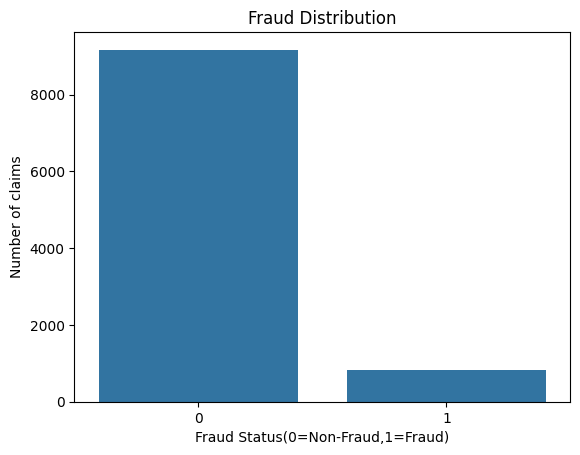

In [113]:
sns.countplot(data=df,x='Is_Fraud')
plt.title('Fraud Distribution')
plt.xlabel('Fraud Status(0=Non-Fraud,1=Fraud)')
plt.ylabel('Number of claims')
plt.show()

This graph shows the distribution of fraudulent and non-fraudulent claims.Out of 10,000 claims, 829 were fraudulent and 9,171 were non-fraudulent.The fraud rate was 8.29%.

**HISTOGRAM**

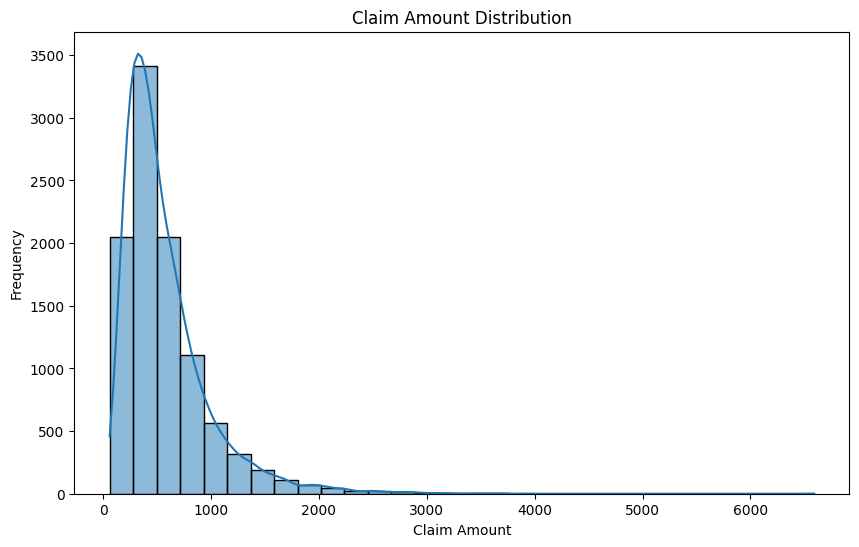

In [114]:
plt.figure(figsize=(10,6))
sns.histplot(data=df,x='Claim_Amount',bins=30,kde=True)
plt.title('Claim Amount Distribution')
plt.xlabel('Claim Amount')
plt.ylabel('Frequency')
plt.show()

This histogram shows the distribution of claim amounts.Most claims have relatively low amounts, while a few claims have very high amounts.

**HISTOGRAM**

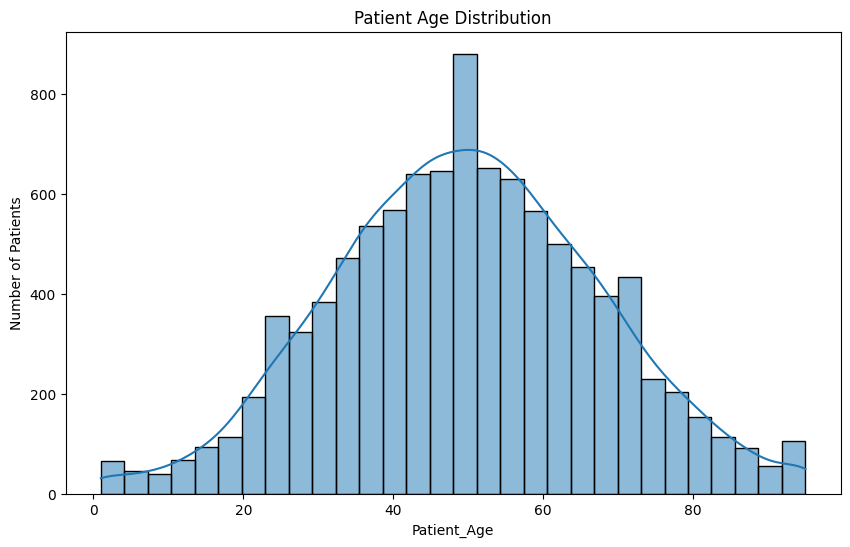

In [115]:
plt.figure(figsize=(10,6))
sns.histplot(data=df,x='Patient_Age',bins=30,kde=True)

plt.title('Patient Age Distribution')
plt.xlabel('Patient_Age')
plt.ylabel('Number of Patients')
plt.show()

This graph shows the age distribution of patients.The average patient age is approximately 50 years.

**COUNT PLOT**

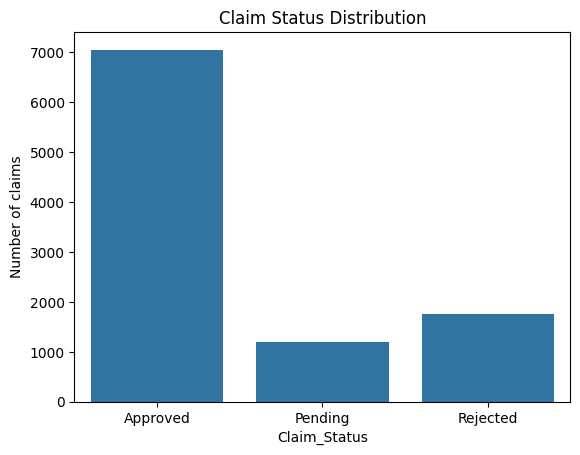

In [116]:
sns.countplot(data=df,x='Claim_Status')
plt.title('Claim Status Distribution')
plt.xlabel('Claim_Status')
plt.ylabel('Number of claims')
plt.show()

This graph shows the status of insurance claims.Most claims were approved, followed by rejected and pending claims.

**COUNT PLOT**

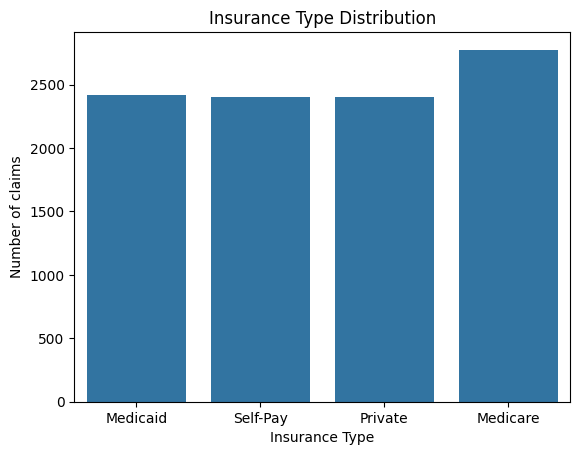

In [117]:
sns.countplot(data=df,x='Insurance_Type')
plt.title('Insurance Type Distribution')
plt.xlabel('Insurance Type')
plt.ylabel('Number of claims')
plt.show()

This graph shows the distribution of claims across different insurance types.Medicare has the highest total number of claims.

**COUNT PLOT**

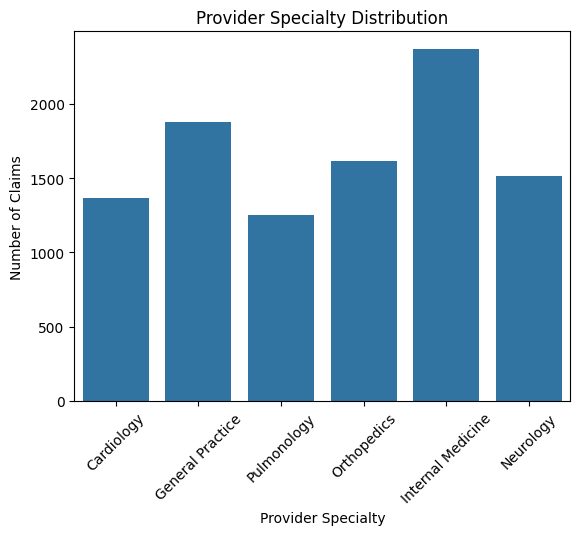

In [118]:
sns.countplot(data=df, x='Provider_Specialty')

plt.title('Provider Specialty Distribution')
plt.xlabel('Provider Specialty')
plt.ylabel('Number of Claims')
plt.xticks(rotation=45)
plt.show()

This graph shows the number of claims across different provider specialties.Internal Medicine has the highest number of claims, followed by General Practice and Orthopedics.

#**BIVARIATE ANALYSIS**

**BOX PLOT**

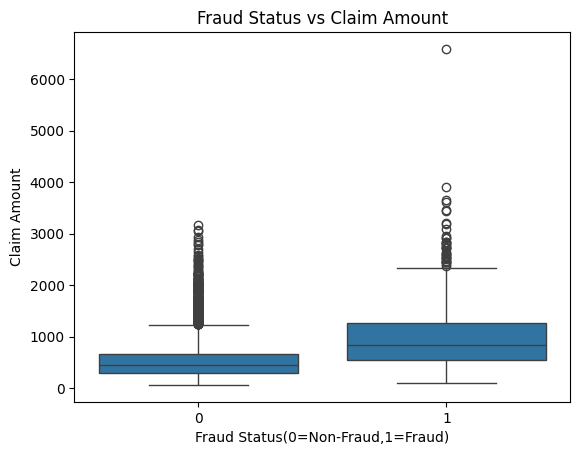

In [119]:
sns.boxplot(data=df,x='Is_Fraud',y='Claim_Amount')
plt.title('Fraud Status vs Claim Amount')
plt.xlabel('Fraud Status(0=Non-Fraud,1=Fraud)')
plt.ylabel('Claim Amount')
plt.show()

This boxplot compares claim amounts between fraudulent and non-fraudulent claims.Fraudulent claims generally show a higher median claim amount than non-fraudulent claims.

**BAR PLOT**

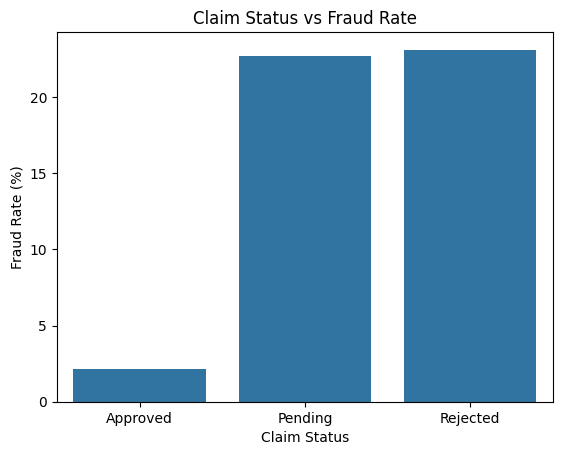

In [120]:
fraud_rate = df.groupby('Claim_Status')['Is_Fraud'].mean() * 100

sns.barplot(x=fraud_rate.index, y=fraud_rate.values)

plt.title('Claim Status vs Fraud Rate')
plt.xlabel('Claim Status')
plt.ylabel('Fraud Rate (%)')
plt.show()

This graph compares fraud rates across different claim statuses.Rejected and pending claims show higher fraud rates than approved claims.

**COUNT PLOT**

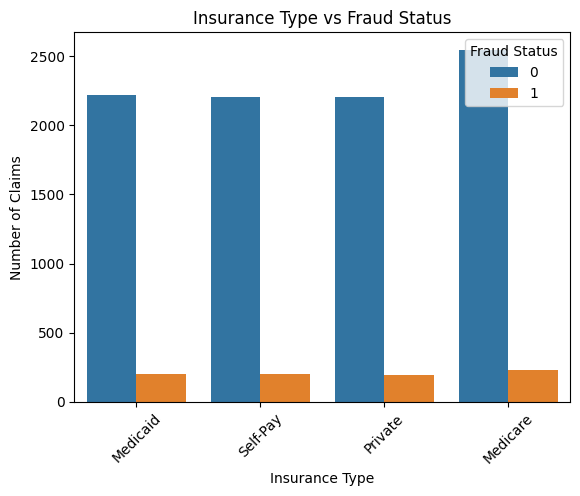

In [121]:
sns.countplot(data=df, x='Insurance_Type', hue='Is_Fraud')

plt.title('Insurance Type vs Fraud Status')
plt.xlabel('Insurance Type')
plt.ylabel('Number of Claims')
plt.xticks(rotation=45)
plt.legend(title='Fraud Status')
plt.show()

This graph compares fraudulent and non-fraudulent claims across insurance types.
Fraudulent claims are present in all four insurance categories.

**BAR PLOT**

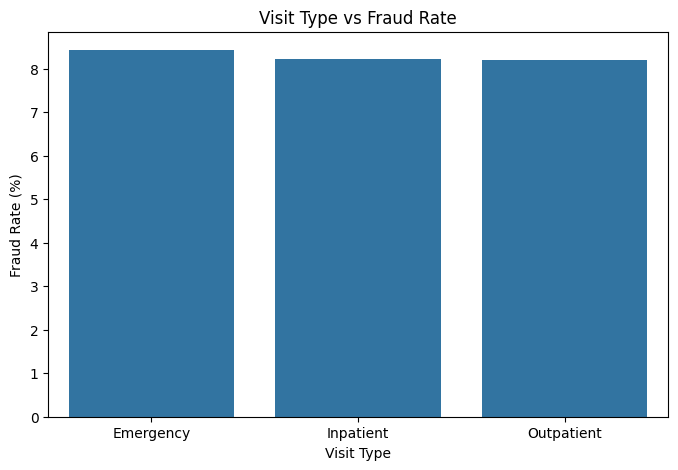

In [122]:
fraud_rate = df.groupby('Visit_Type')['Is_Fraud'].mean() * 100

plt.figure(figsize=(8,5))

sns.barplot(x=fraud_rate.index, y=fraud_rate.values)

plt.title('Visit Type vs Fraud Rate')
plt.xlabel('Visit Type')
plt.ylabel('Fraud Rate (%)')
plt.show()

This graph compares fraud rates across Emergency, Inpatient, and Outpatient visits.Emergency visits show the highest fraud rate, while Inpatient and Outpatient visits have nearly similar rates.

**BAR PLOT**

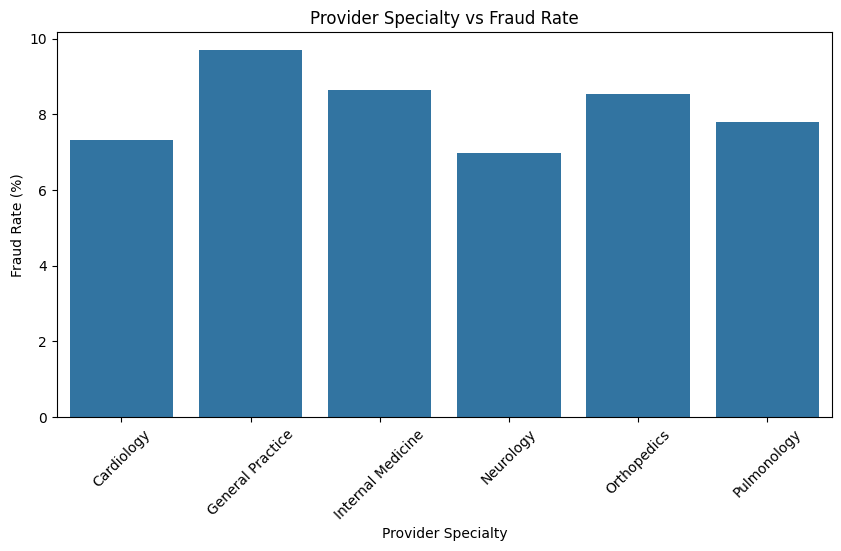

In [123]:
fraud_rate = df.groupby('Provider_Specialty')['Is_Fraud'].mean() * 100

plt.figure(figsize=(10,5))

sns.barplot(x=fraud_rate.index, y=fraud_rate.values)

plt.title('Provider Specialty vs Fraud Rate')
plt.xlabel('Provider Specialty')
plt.ylabel('Fraud Rate (%)')
plt.xticks(rotation=45)
plt.show()

This graph compares fraud rates across provider specialties.
General Practice has the highest fraud rate, followed by Internal Medicine and Orthopedics. Neurology has the lowest rate.

#**MULTIVARIATE ANALYSIS**

**SCATTER PLOT**

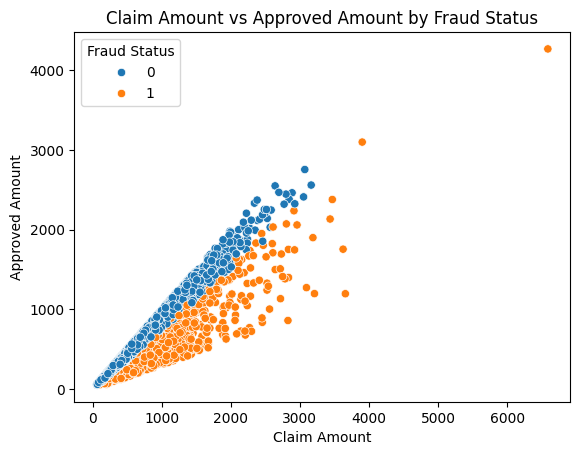

In [124]:
sns.scatterplot(data=df, x='Claim_Amount',
                y='Approved_Amount', hue='Is_Fraud')

plt.title('Claim Amount vs Approved Amount by Fraud Status')
plt.xlabel('Claim Amount')
plt.ylabel('Approved Amount')
plt.legend(title='Fraud Status')
plt.show()

This scatter plot examines the relationship between claim amount and approved amount.The analysis shows a strong positive correlation of 0.94 between these two variables.

**SCATTER PLOT**

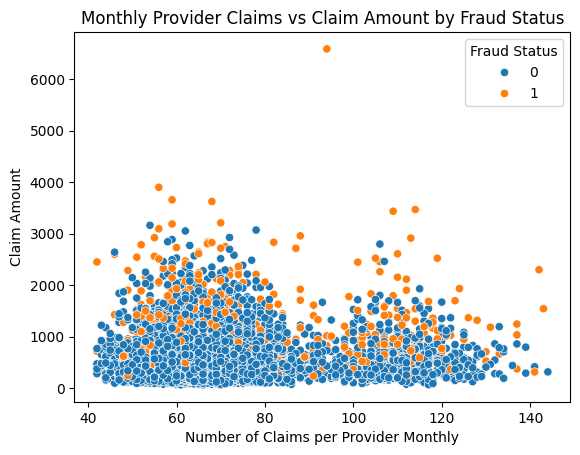

In [125]:
sns.scatterplot(data=df,
                x='Number_of_Claims_Per_Provider_Monthly',
                y='Claim_Amount',
                hue='Is_Fraud')

plt.title('Monthly Provider Claims vs Claim Amount by Fraud Status')
plt.xlabel('Number of Claims per Provider Monthly')
plt.ylabel('Claim Amount')
plt.legend(title='Fraud Status')
plt.show()

This scatter plot examines the relationship between monthly provider claims and claim amounts based on fraud status.Fraudulent claims appear across different claim amounts and provider claim frequencies.

**HEATMAP**

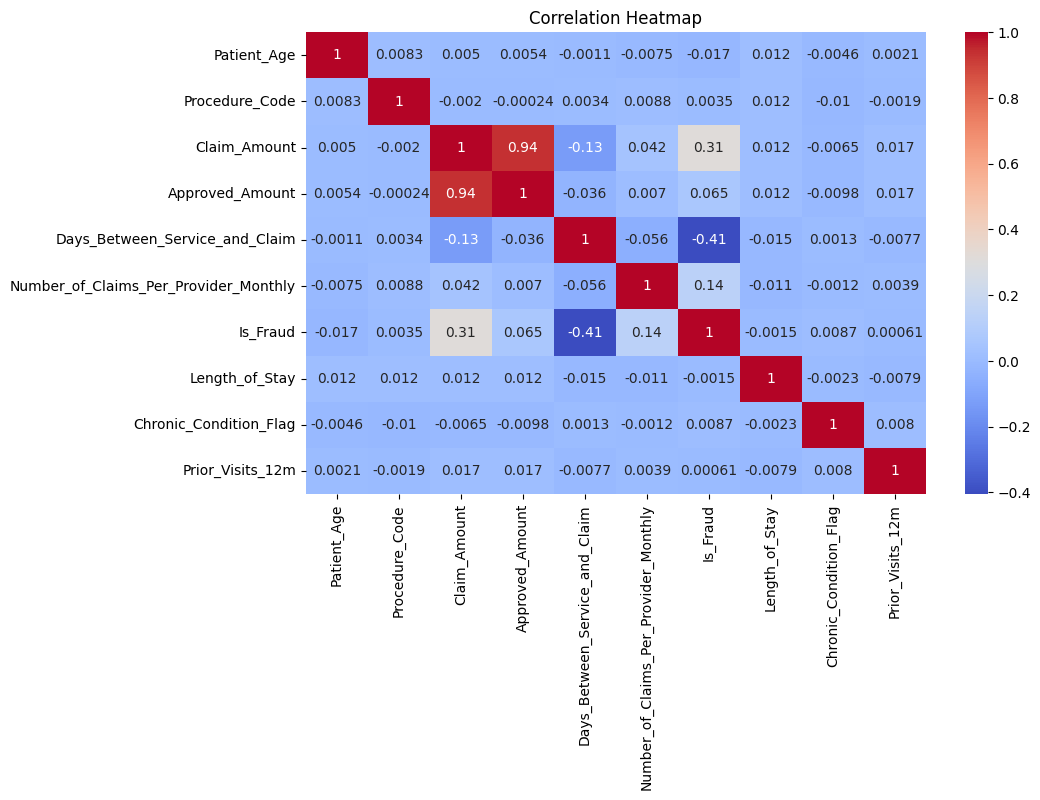

In [126]:
plt.figure(figsize=(10, 6))

sns.heatmap(df.corr(numeric_only=True),
            annot=True, cmap='coolwarm')

plt.title('Correlation Heatmap')
plt.show()

The correlation heatmap shows the relationships between numerical variables.
Claim Amount and Approved Amount have a strong positive correlation of 0.94.
Fraud status has a positive correlation with Claim Amount (0.31) and a negative correlation with Days Between Service and Claim (-0.41).

**CLEANED DATASET**

In [127]:
df.to_csv("Insurance_Fraud_Cleaned.csv", index=False)

In [128]:
df

,Provider_ID,Claim_ID,Patient_Age,Patient_Gender,Diagnosis_Code,Procedure_Code,Claim_Amount,Approved_Amount,Insurance_Type,Claim_Submission_Date,Days_Between_Service_and_Claim,Number_of_Claims_Per_Provider_Monthly,Provider_Specialty,Patient_State,Claim_Status,Is_Fraud,Length_of_Stay,Visit_Type,Chronic_Condition_Flag,Prior_Visits_12m
0,P0052,C0000000,37,Male,I25.10,36415,443.51,393.16,Medicaid,2024-09-01,13,70,Cardiology,NY,Approved,0,0,Outpatient,1,2.0
1,P0121,C0000001,21,Female,E11.9,99213,467.50,461.33,Self-Pay,2022-09-05,5,62,General Practice,IL,Pending,0,5,Inpatient,1,2.0
2,P0140,C0000002,78,Female,J06.9,93000,591.69,530.06,Medicaid,2022-04-11,29,60,Cardiology,IL,Pending,0,5,Inpatient,1,3.0
3,P0202,C0000003,65,Male,I10,93000,235.15,189.11,Private,2023-10-11,22,70,General Practice,TX,Approved,0,0,Emergency,0,5.0
4,P0135,C0000004,36,Male,M54.5,85025,487.96,369.91,Private,2023-09-05,21,67,Pulmonology,PA,Approved,0,5,Inpatient,0,4.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,P0289,C0009995,79,Male,E78.5,71046,590.19,205.00,Private,2024-09-24,2,115,Internal Medicine,PA,Approved,1,2,Inpatient,1,3.0
9996,P0248,C0009996,66,Male,K21.9,93000,219.73,191.89,Self-Pay,2023-01-04,6,73,Orthopedics,IL,Approved,0,5,Inpatient,0,6.0
9997,P0122,C0009997,43,Female,F41.9,99213,505.24,447.94,Medicare,2024-06-30,6,59,Neurology,OH,Rejected,0,5,Emergency,1,0.0
9998,P0072,C0009998,39,Female,I10,93000,564.25,507.18,Medicare,2022-03-15,8,55,Cardiology,TX,Pending,0,5,Emergency,0,6.0


**RECOMMENDATIONS**

1.High-value claims should be carefully verified.

2.Suspicious claim patterns should be monitored.

3.Rejected and pending claims should be reviewed carefully.

4.Healthcare providers with unusual claim patterns should be monitored.

#**CONCLUSION**

The EDA project identified important patterns related to insurance fraud using Python. Claim amount, claim status, visit type, and provider specialty showed useful relationships with fraud. These findings can support better insurance claim analysis and verification.